# Terrain, slope, and basin features: EDA, cleaning, and preparation

Read `raw_dataset/6_static_terrain_soil.csv`, explore the original data, clean and prepare the fields, explore the prepared data, then save the result in `clean_dataset/static_terrain_soil_clean.csv`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")
SOURCE_FILE = '6_static_terrain_soil.csv'
OUTPUT_FILE = 'static_terrain_soil_clean.csv'
DATASET_TITLE = 'Terrain, slope, and basin features'
MEASUREMENT_COLUMNS = ['area_km2', 'lat', 'lon', 'elevation_m', 'elev_min_m', 'elev_max_m', 'slope_deg', 'tpi_2km_m', 'bowl_frac', 'hand_m', 'frac_hand_lt5', 'frac_hand_lt10', 'twi', 'upstream_area_max_km2', 'clay_pct', 'sand_pct', 'soil_texture_class', 'lc_tree', 'lc_crop', 'impervious_built_frac', 'lc_water', 'lc_wetland', 'lc_mangrove', 'river_km_per_km2', 'river_max_cms']
PLOT_COLUMNS = ['elevation_m', 'slope_deg', 'bowl_frac', 'hand_m']
HAS_DATE = False
SPECIAL_DATASET = ''
KEY_COLUMNS = ["date", "unit_level", "district_code"] if HAS_DATE else ["unit_level", "district_code"]

project_dir = next(
    (path for path in [Path.cwd(), *Path.cwd().parents]
     if (path / "raw_dataset" / SOURCE_FILE).is_file()),
    None,
)
if project_dir is None:
    raise FileNotFoundError(f"Cannot find raw_dataset/{SOURCE_FILE} from {Path.cwd()}")
source_path = project_dir / "raw_dataset" / SOURCE_FILE
raw_df = pd.read_csv(source_path, encoding="utf-8-sig")
required_columns = set(KEY_COLUMNS + MEASUREMENT_COLUMNS)
missing_columns = sorted(required_columns - set(raw_df.columns))
if missing_columns:
    raise ValueError(f"Required columns missing from {SOURCE_FILE}: {missing_columns}")


def show_eda(frame, stage):
    print(f"{stage}: {len(frame):,} rows x {len(frame.columns)} columns")
    if HAS_DATE:
        dates = pd.to_datetime(frame["date"], errors="coerce")
        print(f"Date range: {dates.min().date()} to {dates.max().date()}")
    available_measurements = [column for column in MEASUREMENT_COLUMNS if column in frame.columns]
    missing = frame[available_measurements].isna().mean().mul(100).sort_values()
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    missing.tail(15).plot(kind="barh", ax=axes[0], color="darkorange")
    axes[0].set(title=f"{stage}: missing measurements", xlabel="Missing (%)")
    if HAS_DATE:
        plot_cols = [column for column in PLOT_COLUMNS if column in frame.columns]
        date_frame = frame.assign(date=pd.to_datetime(frame["date"], errors="coerce"))
        monthly = date_frame.dropna(subset=["date"]).set_index("date")[plot_cols].resample("MS").mean()
        monthly.plot(ax=axes[1])
        axes[1].set(title=f"{stage}: monthly measurements", xlabel="Date")
        axes[1].legend(fontsize=8)
    else:
        if {"lon", "lat", "elevation_m"}.issubset(frame.columns):
            sns.scatterplot(data=frame, x="lon", y="lat", hue="elevation_m", palette="viridis", ax=axes[1])
            axes[1].set_title(f"{stage}: elevation by location")
        else:
            axes[1].axis("off")
    plt.tight_layout()
    plt.show()

    plot_cols = [column for column in PLOT_COLUMNS if column in frame.columns]
    fig, axes = plt.subplots(2, 2, figsize=(13, 9))
    for column, ax in zip(plot_cols, axes.flat):
        sns.histplot(data=frame, x=column, bins=35, kde=True, ax=ax, color="teal")
        ax.set_title(f"{stage}: {column}")
    for ax in axes.flat[len(plot_cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


In [2]:
print(f"Source: {source_path}")
print("Rows by unit level:")
display(raw_df["unit_level"].value_counts(dropna=False).to_frame("rows"))
print("Data types:")
display(raw_df.dtypes.astype(str).rename("dtype").to_frame())
print("Sample:")
display(raw_df.head())


Source: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\raw_dataset\6_static_terrain_soil.csv
Rows by unit level:


,rows
unit_level,
amphoe,18
province,1


Data types:


,dtype
unit_level,object
province,object
district,object
district_code,int64
area_km2,float64
lat,float64
lon,float64
elevation_m,float64
elev_min_m,float64
elev_max_m,float64


Sample:


,unit_level,province,district,district_code,area_km2,lat,lon,elevation_m,elev_min_m,elev_max_m,...,sand_pct,soil_texture_class,lc_tree,lc_crop,impervious_built_frac,lc_water,lc_wetland,lc_mangrove,river_km_per_km2,river_max_cms
0,amphoe,นครศรีธรรมราช,Bang Khan,26738,472.431869,8.006266,99.489173,95.382076,NaN,NaN,...,50.403300,NaN,0.934469,0.010361,0.004723,0.000418,0.000000,0.0,0.345977,46.043
1,amphoe,นครศรีธรรมราช,Cha-uat,26739,782.117424,7.956940,99.986625,24.432782,NaN,NaN,...,45.660017,NaN,0.813197,0.027253,0.006604,0.007410,0.022857,0.0,0.430348,30.417
2,amphoe,นครศรีธรรมราช,Chawang,26740,874.657452,8.436024,99.526562,177.339235,NaN,NaN,...,49.282396,NaN,0.942864,0.003983,0.008794,0.005915,0.000090,0.0,0.376954,62.032
3,amphoe,นครศรีธรรมราช,Chian Yai,26741,435.951812,8.127505,100.134991,5.118410,NaN,NaN,...,42.421583,NaN,0.641247,0.185035,0.012641,0.020773,0.003250,0.0,0.374401,65.622
4,amphoe,นครศรีธรรมราช,Hua Sai,26742,412.137905,8.008044,100.245939,4.376262,NaN,NaN,...,37.645154,NaN,0.493577,0.299671,0.020450,0.059685,0.002134,0.0,0.315919,3.176


## 1. EDA on the original data

Missing measurements:


,missing_rows
elev_min_m,19
elev_max_m,19
soil_texture_class,19
upstream_area_max_km2,19
river_max_cms,1
elevation_m,0
area_km2,0
lon,0
lat,0
bowl_frac,0


Exact duplicate rows: 0
Duplicate key rows: 0
Measurement summary:


,count,mean,std,min,25%,50%,75%,max
area_km2,19.0,1042.2082,2162.9277,1.7081,383.4767,559.0910,749.5247,9902.0165
lat,19.0,8.4298,0.3883,7.9569,8.1423,8.3736,8.5685,9.3315
lon,19.0,99.8040,0.2367,99.3752,99.6284,99.7914,99.9552,100.2459
elevation_m,19.0,127.6148,123.6518,4.3763,20.5807,95.3821,174.4838,392.8114
elev_min_m,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
elev_max_m,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
slope_deg,19.0,6.7479,4.2379,1.1815,3.3432,6.0022,9.1657,14.4723
tpi_2km_m,19.0,0.7555,2.7054,-4.5555,-0.1218,0.1162,1.0425,9.5629
bowl_frac,19.0,0.1675,0.0862,0.0000,0.1211,0.1773,0.2309,0.3296
hand_m,19.0,35.6630,32.7724,0.6763,5.9674,25.0756,53.1937,97.0685


Original data: 19 rows x 29 columns


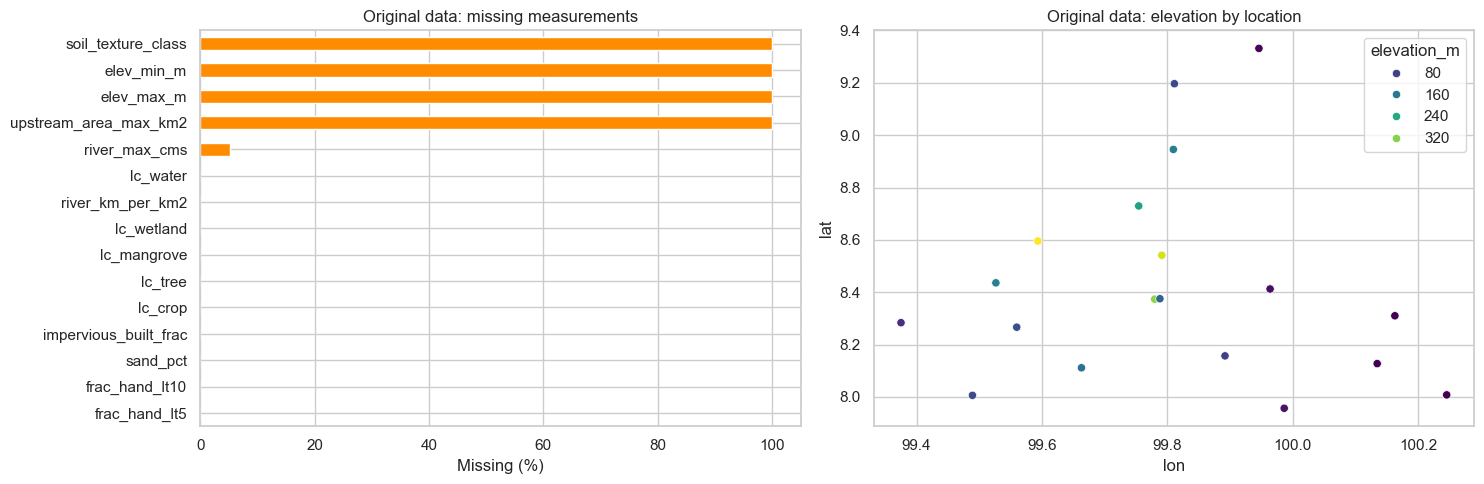

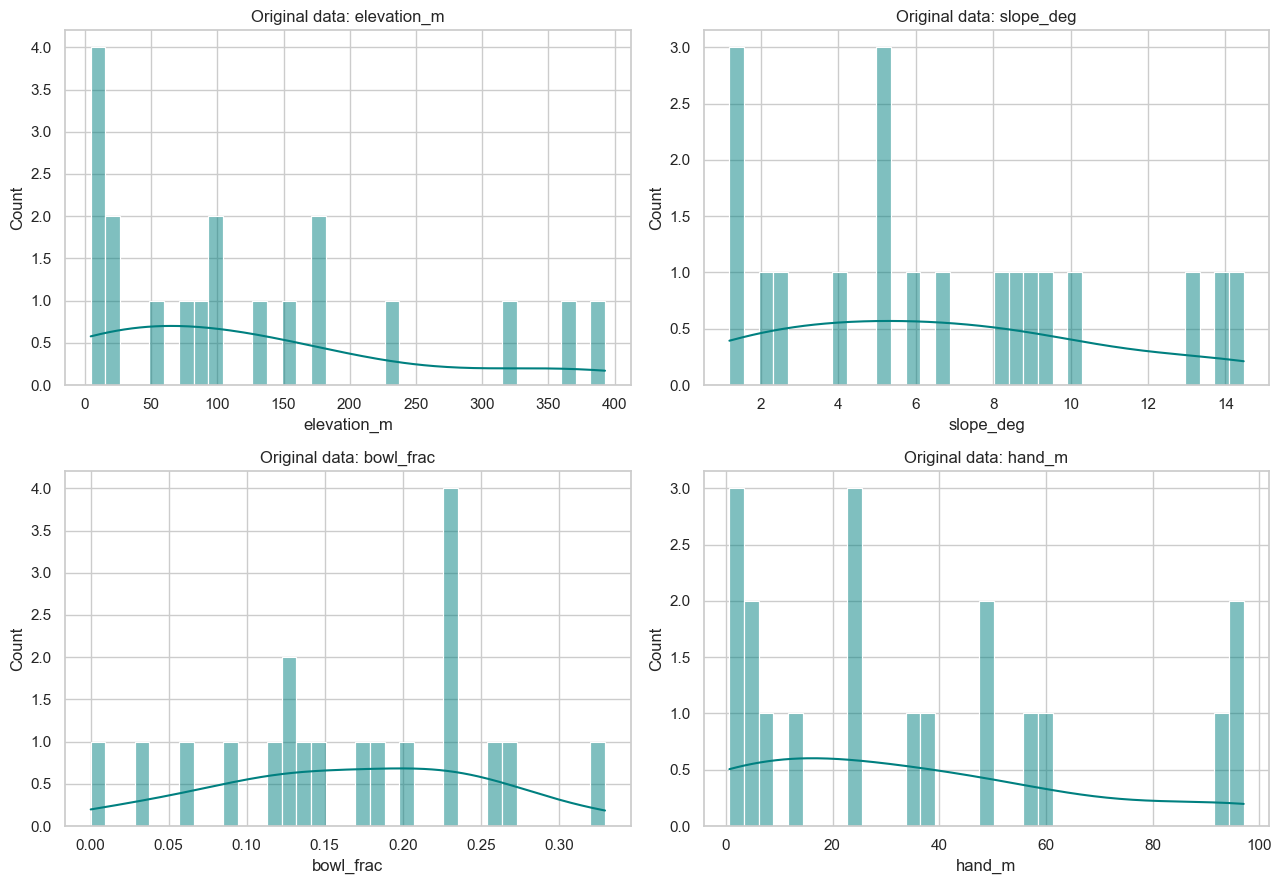

In [3]:
eda_df = raw_df.copy()
if HAS_DATE:
    eda_df["date"] = pd.to_datetime(eda_df["date"], errors="coerce")
print("Missing measurements:")
display(eda_df[MEASUREMENT_COLUMNS].isna().sum().sort_values(ascending=False).rename("missing_rows").to_frame())
print("Exact duplicate rows:", int(eda_df.duplicated().sum()))
print("Duplicate key rows:", int(eda_df.duplicated(KEY_COLUMNS).sum()))
print("Measurement summary:")
display(eda_df[MEASUREMENT_COLUMNS].describe().T.round(4))
show_eda(eda_df, "Original data")


## 2. Clean the data

Normalize dates, text and numeric types, and remove invalid keys or duplicate records. Keep missing source measurements intact; do not treat unavailable observations as zero.

In [4]:
df_clean = raw_df.copy()
rows_before = len(df_clean)
if HAS_DATE:
    df_clean["date"] = pd.to_datetime(df_clean["date"], errors="coerce")

text_columns = df_clean.select_dtypes(include=["object", "string"]).columns
for column in text_columns:
    df_clean[column] = (df_clean[column].astype("string").str.strip()
                        .str.replace(r"\s+", " ", regex=True))
df_clean["district_code"] = pd.to_numeric(df_clean["district_code"], errors="coerce")
for column in MEASUREMENT_COLUMNS:
    df_clean[column] = pd.to_numeric(df_clean[column], errors="coerce")

df_clean = df_clean.dropna(subset=KEY_COLUMNS).copy()
df_clean["district_code"] = df_clean["district_code"].astype("int64")
df_clean = df_clean.drop_duplicates()
df_clean = df_clean.drop_duplicates(subset=KEY_COLUMNS, keep="first")
print(f"Rows before cleaning: {rows_before:,}")
print(f"Rows after cleaning: {len(df_clean):,}")
print(f"Rows removed: {rows_before - len(df_clean):,}")
print("Remaining missing measurements (not imputed):")
display(df_clean[MEASUREMENT_COLUMNS].isna().sum().sort_values(ascending=False).rename("missing_rows").to_frame())
display(df_clean.head())


Rows before cleaning: 19
Rows after cleaning: 19
Rows removed: 0
Remaining missing measurements (not imputed):


,missing_rows
elev_min_m,19
elev_max_m,19
soil_texture_class,19
upstream_area_max_km2,19
river_max_cms,1
elevation_m,0
area_km2,0
lon,0
lat,0
bowl_frac,0


,unit_level,province,district,district_code,area_km2,lat,lon,elevation_m,elev_min_m,elev_max_m,...,sand_pct,soil_texture_class,lc_tree,lc_crop,impervious_built_frac,lc_water,lc_wetland,lc_mangrove,river_km_per_km2,river_max_cms
0,amphoe,นครศรีธรรมราช,Bang Khan,26738,472.431869,8.006266,99.489173,95.382076,NaN,NaN,...,50.403300,NaN,0.934469,0.010361,0.004723,0.000418,0.000000,0.0,0.345977,46.043
1,amphoe,นครศรีธรรมราช,Cha-uat,26739,782.117424,7.956940,99.986625,24.432782,NaN,NaN,...,45.660017,NaN,0.813197,0.027253,0.006604,0.007410,0.022857,0.0,0.430348,30.417
2,amphoe,นครศรีธรรมราช,Chawang,26740,874.657452,8.436024,99.526562,177.339235,NaN,NaN,...,49.282396,NaN,0.942864,0.003983,0.008794,0.005915,0.000090,0.0,0.376954,62.032
3,amphoe,นครศรีธรรมราช,Chian Yai,26741,435.951812,8.127505,100.134991,5.118410,NaN,NaN,...,42.421583,NaN,0.641247,0.185035,0.012641,0.020773,0.003250,0.0,0.374401,65.622
4,amphoe,นครศรีธรรมราช,Hua Sai,26742,412.137905,8.008044,100.245939,4.376262,NaN,NaN,...,37.645154,NaN,0.493577,0.299671,0.020450,0.059685,0.002134,0.0,0.315919,3.176


## 3. Prepare the data

Add missing-data indicators where source measurements are missing, rebuild calendar fields where applicable, sort by the dataset keys, and preserve the original measurements without imputation.

In [5]:
df_prepared = df_clean.copy()
required_columns = set(KEY_COLUMNS)
all_empty_columns = [column for column in df_prepared.columns
                     if column not in required_columns and df_prepared[column].isna().all()]
df_prepared = df_prepared.drop(columns=all_empty_columns)

flagged_columns = [column for column in MEASUREMENT_COLUMNS
                   if column in df_prepared.columns and df_prepared[column].isna().any()]
for column in flagged_columns:
    df_prepared[f"{column}_missing"] = df_prepared[column].isna().astype("int8")

if SPECIAL_DATASET == "flood":
    df_prepared["flood_obs_available"] = df_prepared["flood_obs"].notna().astype("int8")
    if not df_prepared["flood_obs"].dropna().isin([0, 1]).all():
        raise ValueError("flood_obs must contain only 0, 1, or missing values")
elif SPECIAL_DATASET == "river":
    df_prepared["river_observation_available"] = df_prepared["n_scenes"].gt(0).astype("int8")

if HAS_DATE:
    df_prepared["year"] = df_prepared["date"].dt.year.astype("int16")
    df_prepared["month"] = df_prepared["date"].dt.month.astype("int8")
    df_prepared["day"] = df_prepared["date"].dt.day.astype("int8")
    df_prepared["doy"] = df_prepared["date"].dt.dayofyear.astype("int16")

df_prepared = df_prepared.sort_values(KEY_COLUMNS).reset_index(drop=True)
assert df_prepared[KEY_COLUMNS].notna().all().all()
assert not df_prepared.duplicated(KEY_COLUMNS).any()
print(f"Prepared shape: {df_prepared.shape}")
print(f"All-empty columns removed: {all_empty_columns}")
print(f"Missing-indicator columns added: {flagged_columns}")
print("Missing measurements remain available for review; no values were imputed.")


Prepared shape: (19, 26)
All-empty columns removed: ['elev_min_m', 'elev_max_m', 'upstream_area_max_km2', 'soil_texture_class']
Missing-indicator columns added: ['river_max_cms']
Missing measurements remain available for review; no values were imputed.


## 4. EDA on the cleaned and prepared data

Prepared data types:


,dtype
unit_level,string
province,string
district,string
district_code,int64
area_km2,float64
lat,float64
lon,float64
elevation_m,float64
slope_deg,float64
tpi_2km_m,float64


Prepared measurement summary:


,count,mean,std,min,25%,50%,75%,max
area_km2,19.0,1042.2082,2162.9277,1.7081,383.4767,559.0910,749.5247,9902.0165
lat,19.0,8.4298,0.3883,7.9569,8.1423,8.3736,8.5685,9.3315
lon,19.0,99.8040,0.2367,99.3752,99.6284,99.7914,99.9552,100.2459
elevation_m,19.0,127.6148,123.6518,4.3763,20.5807,95.3821,174.4838,392.8114
slope_deg,19.0,6.7479,4.2379,1.1815,3.3432,6.0022,9.1657,14.4723
tpi_2km_m,19.0,0.7555,2.7054,-4.5555,-0.1218,0.1162,1.0425,9.5629
bowl_frac,19.0,0.1675,0.0862,0.0000,0.1211,0.1773,0.2309,0.3296
hand_m,19.0,35.6630,32.7724,0.6763,5.9674,25.0756,53.1937,97.0685
frac_hand_lt5,19.0,0.5513,0.2715,0.1775,0.3627,0.4408,0.7831,0.9910
frac_hand_lt10,19.0,0.6567,0.2323,0.2432,0.5096,0.6334,0.8657,0.9998


Missing values by prepared column:


,missing_rows
river_max_cms,1
unit_level,0
district,0
district_code,0
area_km2,0
lat,0
lon,0
elevation_m,0
slope_deg,0
province,0


Cleaned and prepared data: 19 rows x 26 columns


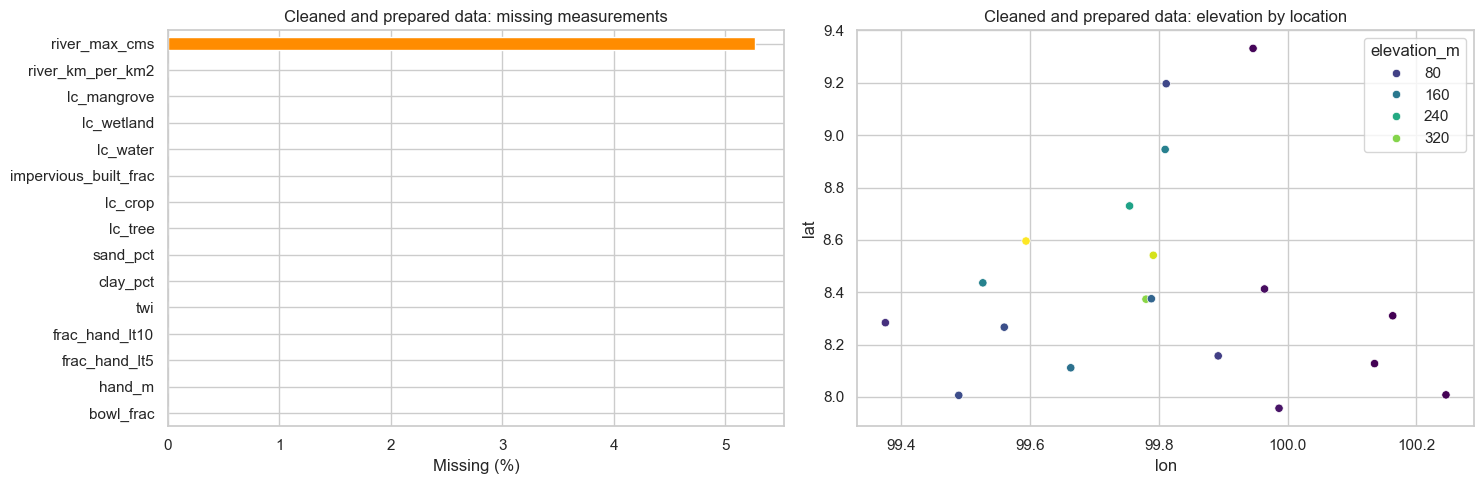

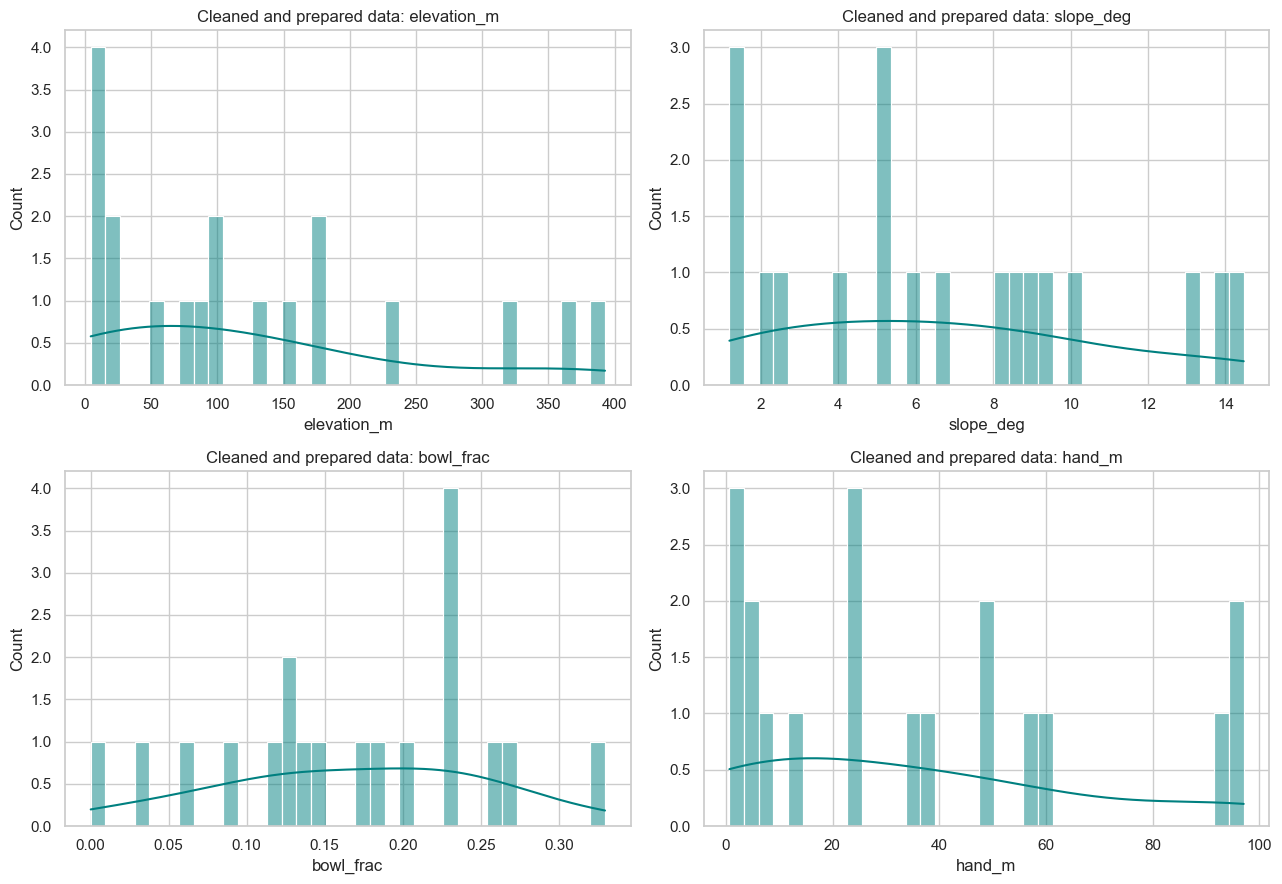

In [6]:
print("Prepared data types:")
display(df_prepared.dtypes.astype(str).rename("dtype").to_frame())
print("Prepared measurement summary:")
remaining_measurements = [column for column in MEASUREMENT_COLUMNS if column in df_prepared.columns]
display(df_prepared[remaining_measurements].describe().T.round(4))
print("Missing values by prepared column:")
display(df_prepared.isna().sum().sort_values(ascending=False).head(20).rename("missing_rows").to_frame())
show_eda(df_prepared, "Cleaned and prepared data")


## 5. Save the prepared data

In [7]:
output_dir = project_dir / "clean_dataset"
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / OUTPUT_FILE
df_prepared.to_csv(output_path, index=False, date_format="%Y-%m-%d", encoding="utf-8-sig")

read_options = {"encoding": "utf-8-sig"}
if HAS_DATE:
    read_options["parse_dates"] = ["date"]
saved_df = pd.read_csv(output_path, **read_options)
assert saved_df.shape == df_prepared.shape
assert not saved_df.duplicated(KEY_COLUMNS).any()
print(f"Saved: {output_path}")
print(f"File size: {output_path.stat().st_size:,} bytes")
print(f"CSV shape: {saved_df.shape}")


Saved: c:\Users\sitti\OneDrive\Desktop\Nahh ahhh v4\clean_dataset\static_terrain_soil_clean.csv
File size: 8,451 bytes
CSV shape: (19, 26)
